# Despliegue: API, contenedor, integración continua y registro de modelos

En este capítulo describimos cómo los dos modelos elegidos llegan a producción y qué garantías comprobamos en el camino: paridad numérica tras la exportación, efecto de la cuantización, regresión sobre un conjunto dorado, comportamiento bajo carga y trazabilidad de cada versión. Los resultados los generan los trabajos `mlops_export_seg`, `mlops_export_text`, `mlops_bert_quant` y `mlops_load` de la cola.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, exists, need, style

style()
pd.set_option("display.precision", 3)
md = lambda t: display(Markdown(t))  # noqa: E731

## Arquitectura

```text
 results/ (pickles y pesos)
       │  scripts/mlops.py export-seg | export-text   (paridad, cuantización, conjunto dorado)
       ▼
 models/serving/{text,seg}/  model.onnx o model.pkl + meta.json + golden.json ──► MLflow: registro de versiones
       │  docker build (multi-etapa, usuario no root)                              (staging / production / previous)
       ▼
 API FastAPI  /health /ready /model_info /metrics /metrics/prometheus /predict_text /predict_image
       │  PRED_LOG (JSONL con señales agregadas, sin textos ni imágenes)
       ▼
 Monitoreo de deriva por ventanas (capítulo 31)
```

| Ruta | Entrada | Salida | Validación |
|---|---|---|---|
| `GET /health` | — | estado del proceso | — |
| `GET /ready` | — | 200 si los dos modelos cargaron; 503 con el error si no | — |
| `GET /model_info` | — | nombre, versión, posproceso y métricas de validación de cada modelo | — |
| `GET /metrics` | — | contadores y latencias p50/p95/p99 por ruta, en JSON | — |
| `GET /metrics/prometheus` | — | las mismas señales en el formato de texto de Prometheus, para un *scrape* y paneles de Grafana | — |
| `POST /predict_text` | JSON `{"text", "top_k"}` | etiqueta, probabilidades de las k primeras clases, versión, latencia | texto de 1 a 100 000 caracteres; `top_k` entre 1 y 24 |
| `POST /predict_image` | archivo PNG/JPEG/TIFF | número de instancias y máscaras en RLE (convención de Kaggle) | lado entre 32 y 2048 px; se convierte a escala de grises |

Cada respuesta lleva un `request_id` que también aparece en los registros JSON del servidor. Con la variable `PRED_LOG` activa, la API escribe por petición solo señales agregadas (longitud, etiqueta y confianza para texto; intensidad, fracción de primer plano y número de instancias para imágenes): **no guarda el texto ni la imagen**, porque los currículos contienen datos personales.

## Exportación, paridad y cuantización

**Segmentación.** Exportamos U-Net++ (la semilla con mejor AP de validación) a ONNX y comparamos sus salidas con las del modelo de Keras en las 92 imágenes de validación. La cuantización estática int8 (formato QDQ, calibración con 32 imágenes de entrenamiento) solo se sirve si el AP cae como máximo 0.01 y la latencia baja.

In [2]:
if exists("mlops/export_seg/export_seg.pkl"):
    ex = need("mlops/export_seg/export_seg.pkl")
    par = ex["parity"]
    _mx = par.max_abs_diff.max()
    md(f"Modelo exportado: {({'unetpp_main': 'U-Net++', 'maskrcnn_main': 'Mask R-CNN'}).get(ex['model'], ex['model'])}, semilla {ex['seed']}. "
       f"Diferencia máxima absoluta entre probabilidades de Keras y ONNX: {_mx:.2e}, "
       + ("dentro de la tolerancia declarada de 10⁻³. " if _mx <= 1e-3 else
          f"por encima de la tolerancia declarada de 10⁻³ en {int((par.max_abs_diff > 1e-3).sum())} de {len(par)} imágenes; la diferencia "
          f"no cambia el resultado del post-proceso de forma apreciable: el AP medio difiere en {abs(par.ap_keras.mean() - par.ap_onnx.mean()):.4f}. ")
       + f"AP de validación: Keras {par.ap_keras.mean():.4f}, ONNX {par.ap_onnx.mean():.4f}. "
       f"Latencia ONNX en CPU por imagen: p50 {1e3 * par.lat_onnx_s.median():.0f} ms.")
    q = ex["quant"]
    if "ap_drop" in q:
        md(f"Cuantización int8: AP {q['ap']:.4f} (caída {q['ap_drop']:+.4f}), latencia p50 {1e3 * q['lat_p50']:.0f} ms, tamaño {q['size_mb']:.1f} MB. "
           f"**{'Se sirve la versión int8.' if ex['served_int8'] else 'Se sirve la versión fp32'}**"
           + ("" if ex["served_int8"] else " porque la versión int8 no cumple a la vez caída ≤ 0.01 y menor latencia."))
    else:
        md(f"La cuantización estática falló: `{q.get('error', '')[:200]}`. Se sirve la versión fp32.")
    md(f"Tamaño del modelo servido: {ex['onnx_mb']:.1f} MB. AP del conjunto dorado (6 imágenes): {ex['golden_ap']:.3f}.")
else:
    md("La exportación de segmentación no terminó (`python scripts/mlops.py export-seg`).")

Modelo exportado: U-Net++, semilla 2. Diferencia máxima absoluta entre probabilidades de Keras y ONNX: 2.21e-03, por encima de la tolerancia declarada de 10⁻³ en 91 de 92 imágenes; la diferencia no cambia el resultado del post-proceso de forma apreciable: el AP medio difiere en 0.0002. AP de validación: Keras 0.2300, ONNX 0.2298. Latencia ONNX en CPU por imagen: p50 1947 ms.

La cuantización estática falló: `Incomplete symbolic shape inference`. Se sirve la versión fp32.

Tamaño del modelo servido: 18.2 MB. AP del conjunto dorado (6 imágenes): 0.125.

**Texto.** La regla de elección se fijó antes de ver test: servimos DistilBERT solo si su F1 macro de validación supera la de TF-IDF + RL en más de δ = 0.02, porque DistilBERT cuesta más en latencia y memoria (medición en el capítulo {doc}`25_nlp_analisis_critico`).

In [3]:
if exists("mlops/export_text/export_text.pkl"):
    et = need("mlops/export_text/export_text.pkl")
    md(f"F1 macro de validación: TF-IDF + RL {et['f1_val_lr']:.3f}, DistilBERT "
       + (f"{et['f1_val_bert']:.3f}" if et.get("f1_val_bert") == et.get("f1_val_bert") and et.get("f1_val_bert") is not None else "—")
       + f". **Modelo servido: {({'distilbert': 'DistilBERT', 'tfidf_lr': 'TF-IDF + RL'}).get(et['choice'], et['choice'])}.** F1 macro del modelo servido en validación: {et['val_f1_served']:.3f}; latencia en CPU por "
       f"documento p50 {et['lat_p50_ms']:.1f} ms, p95 {et['lat_p95_ms']:.1f} ms; exactitud en el conjunto dorado (40 textos): {et['golden_accuracy']:.3f}.")
    if "parity_max_abs" in et:
        md(f"Paridad entre el *pipeline* servido y las probabilidades del entrenamiento: diferencia máxima {et['parity_max_abs']:.2e}.")
else:
    md("La exportación de texto no terminó (`python scripts/mlops.py export-text`).")
if exists("mlops/bert_quant/bert_quant.pkl"):
    bq = need("mlops/bert_quant/bert_quant.pkl")["table"]
    display(bq.rename(columns={"variant": "DistilBERT", "f1_val": "F1 macro (150 docs. val)", "lat_p50_ms": "p50 (ms)", "lat_p95_ms": "p95 (ms)",
                               "size_mb": "tamaño (MB)", "agreement_with_fp32": "acuerdo con fp32"}).style.hide(axis="index").format(precision=3, na_rep="—"))

F1 macro de validación: TF-IDF + RL 0.659, DistilBERT 0.774. **Modelo servido: DistilBERT.** F1 macro del modelo servido en validación: 0.776; latencia en CPU por documento p50 190.3 ms, p95 197.9 ms; exactitud en el conjunto dorado (40 textos): 0.850.

DistilBERT,F1 macro (150 docs. val),p50 (ms),p95 (ms),tamaño (MB),acuerdo con fp32
ONNX fp32,0.351,182.344,200.157,268.012,—
ONNX int8 dinámico,0.351,68.185,73.949,67.380,0.947


## Prueba de carga

Levantamos la API con un solo proceso de uvicorn en CPU y la sometimos a niveles crecientes de usuarios concurrentes con Locust (cada usuario espera entre 0.1 y 0.5 s entre peticiones; 80 % texto, 10 % imagen, 10 % `/health`). Definimos el punto de saturación como el primer nivel a partir del cual duplicar los usuarios aumenta el rendimiento menos de un 10 %.

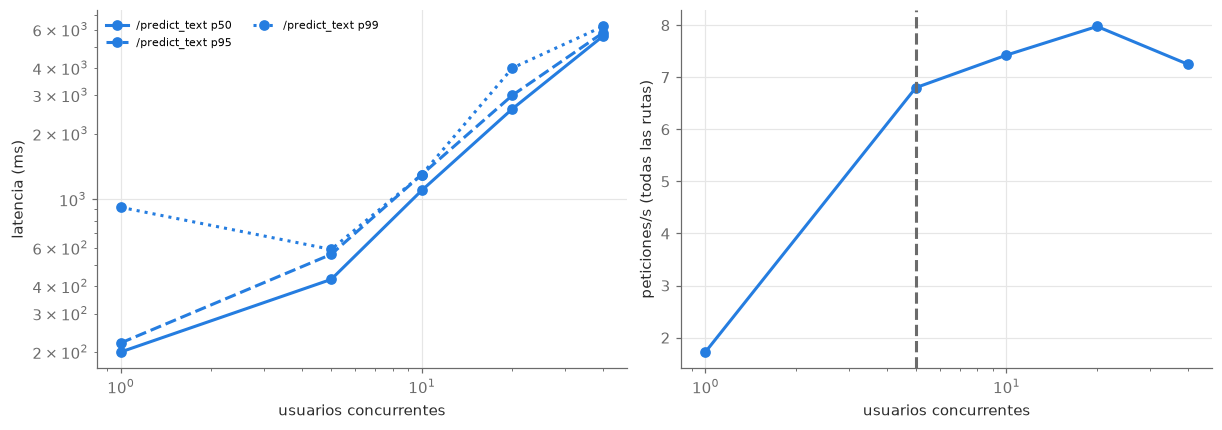

usuarios,ruta,peticiones,fallos,peticiones/s,p50_ms,p95_ms,p99_ms
1,/health,10,0,0.2,3.0,6.0,6.0
1,/predict_text,59,0,1.5,200.0,220.0,920.0
5,/health,33,0,0.8,5.0,8.0,15.0
5,/predict_text,239,0,6.0,430.0,560.0,590.0
10,/health,30,0,0.8,10.0,20.0,27.0
10,/predict_text,267,0,6.7,1100.0,1300.0,1300.0
20,/health,41,0,1.0,12.0,36.0,150.0
20,/predict_text,278,0,7.0,2600.0,3000.0,4000.0
40,/health,34,0,0.8,11.0,250.0,380.0
40,/predict_text,256,0,6.4,5600.0,5800.0,6200.0


La prueba de carga corrió antes de que el modelo de segmentación estuviera exportado, así que solo cubre la ruta de texto y `/health`; la ruta de imágenes no tiene medición bajo carga.

Punto de saturación: 5 usuarios (6.8 peticiones/s).

modelo,modo,elementos/s,error
texto,lote 1,5.3,—
texto,lote 32,5.3,—
segmentación,error,—,[Errno 2] No such file or directory: 'C:\\Users\\User\\Documents\\GitHub\\proyecto-integrador-dl\\models\\serving\\seg\\meta.json'


In [4]:
if exists("mlops/load/load.pkl"):
    ld = need("mlops/load/load.pkl")
    S = ld["sweep"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for k, ep in enumerate(["/predict_text", "/predict_image"]):
        g = S[S.endpoint == ep].set_index("users")
        if len(g):
            for q_, ls in (("p50_ms", "-"), ("p95_ms", "--"), ("p99_ms", ":")):
                axes[0].plot(g.index, g[q_], ls, marker="o", color=CAT[k], label=f"{ep} {q_[:3]}")
    axes[0].set(xscale="log", yscale="log", xlabel="usuarios concurrentes", ylabel="latencia (ms)"); axes[0].legend(fontsize=7, ncol=2)
    agg = S[S.endpoint == "Aggregated"].set_index("users")
    axes[1].plot(agg.index, agg.rps, "o-", color=CAT[0])
    if ld["saturation_users"]:
        axes[1].axvline(ld["saturation_users"], color=MUTED, ls="--")
    axes[1].set(xscale="log", xlabel="usuarios concurrentes", ylabel="peticiones/s (todas las rutas)")
    plt.show()
    display(S[S.endpoint != "Aggregated"][["users", "endpoint", "requests", "failures", "rps", "p50_ms", "p95_ms", "p99_ms"]]
            .rename(columns={"users": "usuarios", "endpoint": "ruta", "requests": "peticiones", "failures": "fallos", "rps": "peticiones/s"})
            .style.hide(axis="index").format(precision=1))
    if not (S.endpoint == "/predict_image").any():
        md("La prueba de carga corrió antes de que el modelo de segmentación estuviera exportado, así que solo cubre la ruta de texto "
           "y `/health`; la ruta de imágenes no tiene medición bajo carga.")
    sat = ld["saturation_users"]
    md(f"Punto de saturación: {sat} usuarios ({agg.rps[sat]:.1f} peticiones/s)." if sat else
       f"No alcanzamos la saturación hasta {max(ld['levels'])} usuarios ({agg.rps.iloc[-1]:.1f} peticiones/s).")
    display(ld["batching"].rename(columns={"model": "modelo", "mode": "modo", "docs_per_s": "elementos/s", "net_ms": "red (ms)",
                                           "post_ms": "posproceso (ms)"}).style.hide(axis="index").format(precision=1, na_rep="—"))
    bs = ld["batching"]
    bs = bs[(bs.model == "segmentación") & bs.post_ms.notna()] if "post_ms" in bs else bs.iloc[0:0]
    if len(bs):
        r = bs.iloc[0]
        md(f"En segmentación, la red ocupa {r.net_ms:.0f} ms y el posproceso por watershed {r.post_ms:.0f} ms por imagen (medianas en CPU): "
           f"el posproceso es el {100 * r.post_ms / (r.net_ms + r.post_ms):.0f} % del tiempo y agrupar imágenes en lotes solo acelera la parte de la red.")
else:
    md("La prueba de carga no terminó (`python scripts/mlops.py load`).")

La API no agrupa peticiones en lotes: cada petición se atiende sola. La tabla de lotes, medida fuera de la API, muestra cuánto rendimiento se ganaría agrupando textos. Con un solo *worker*, la ruta de imágenes bloquea al resto durante su cálculo: en producción la separaríamos en un servicio propio.

## Integración continua

El flujo de GitHub Actions (`.github/workflows/ci.yml`) ejecuta, en orden:

| Etapa | Herramienta | Qué falla |
|---|---|---|
| Estilo | `ruff` | errores de estilo o código muerto |
| Tipos | `mypy` en los módulos de RLE, métricas, estadística, calibración y servicio | inconsistencias de tipos |
| Pruebas unitarias | `pytest` | RLE ida y vuelta y fuera de rango, métricas con casos conocidos (Dice, IoU, AP, HD95, taxonomía de fusiones y divisiones), Holm, escalado de temperatura, cobertura conforme, PSI, escritura atómica, determinismo con semilla |
| Esquema de la API | `pytest` + `TestClient` | esquema de respuesta, rechazo de entradas inválidas, latencia < 5 s por petición |
| Datos | `pandera` y pruebas de fuga | esquema de Sartorius; ningún `sample_id` ni grupo de casi duplicados cruza particiones (se omite sin datos) |
| Regresión de modelo | conjunto dorado | AP o exactitud del modelo servido cae más de ε = 0.02 respecto del registrado |
| Vulnerabilidades de dependencias | `pip-audit` | dependencias de servicio con vulnerabilidades conocidas |
| Imagen | `docker build` | construcción multi-etapa |
| Prueba de humo | contenedor + `curl` | `/health`, `/ready`, `/predict_text` y `/predict_image` responden |
| Vulnerabilidades de la imagen | Trivy | CVE críticas o altas en la imagen |

Los datos de Kaggle no están en el repositorio, así que en GitHub las pruebas de datos se omiten y la prueba de humo usa modelos mínimos generados por `scripts/make_smoke_models.py`; en local, `make test` las ejecuta todas.

## Trazabilidad: MLflow, DVC y tarjetas de modelo

- **MLflow** (`make track`): vuelca todos los resultados de `results/` a un almacén local en SQLite. Cada entrenamiento de segmentación es una corrida con su configuración y su curva de pérdida; cada búsqueda de hiperparámetros de NLP es una corrida madre con una corrida hija por *trial*. Los modelos servidos se registran como versiones con los alias `staging`, `production` y `previous`; `python scripts/track_mlflow.py rollback text` devuelve `production` a la versión anterior.
- **DVC** (`dvc.yaml`): declara las seis etapas de `make reproduce` (datos → particiones → entrenamiento → evaluación → análisis → Book) con sus dependencias, de modo que `dvc repro` solo rehace lo que cambió. Los datos crudos se verifican por SHA-256 y los pesos no se duplican en la caché de DVC.
- **Versión de cada modelo servido**: `meta.json` guarda el nombre, la semilla, el *commit* corto de git como versión, el SHA-256 de los datos y las métricas de validación, y `/model_info` lo expone.

Las tarjetas de modelo se generan desde los pickles con `python scripts/model_cards.py`.

```{include} ../reports/model_cards/segmentacion.md
:heading-offset: 2
```

```{include} ../reports/model_cards/texto.md
:heading-offset: 2
```